In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam


In [2]:
csv_path = "C:\\Users\\devgo\\OneDrive\\Desktop\\project\\data\\GroundTruth.csv"
img_dir = "C:\\Users\\devgo\\OneDrive\\Desktop\\project\\data\\images"
out_dir = "C:\\Users\\devgo\\OneDrive\\Desktop\\project\\data\\processed_images"
os.makedirs(out_dir, exist_ok=True)

df = pd.read_csv(csv_path)
df["image"] = df["image_id"] + ".jpg"
label_cols = ['MEL', 'NV', 'BCC', 'AKIEC', 'BKL', 'DF', 'VASC']

for label in label_cols:
    os.makedirs(os.path.join(out_dir, label), exist_ok=True)

for _, row in df.iterrows():
    img_name = row["image"]
    src = os.path.join(img_dir, img_name)
    for label in label_cols:
        if row[label] == 1 and os.path.exists(src):
            dst = os.path.join(out_dir, label, img_name)
            try:
                Image.open(src).convert("RGB").resize((64, 64)).save(dst)
            except:
                continue


In [3]:
image_counts = df[label_cols].sum().astype(int)
print(image_counts)

MEL      1113
NV       6705
BCC       514
AKIEC     327
BKL      1099
DF        115
VASC      142
dtype: int64


In [4]:
def build_generator():
    model = models.Sequential()
    model.add(layers.Dense(8*8*256, use_bias=False, input_shape=(100,)))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())
    model.add(layers.Reshape((8, 8, 256)))
    model.add(layers.Conv2DTranspose(128, 4, strides=2, padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())
    model.add(layers.Conv2DTranspose(64, 4, strides=2, padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())
    model.add(layers.Conv2DTranspose(3, 4, strides=2, padding='same', use_bias=False, activation='tanh'))
    return model

In [5]:
def build_discriminator():
    model = models.Sequential()
    model.add(layers.Conv2D(64, 4, strides=2, padding='same', input_shape=(64, 64, 3)))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))
    model.add(layers.Conv2D(128, 4, strides=2, padding='same'))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))
    model.add(layers.Flatten())
    model.add(layers.Dense(1))
    return model

In [7]:
BATCH_SIZE = 64
NOISE_DIM = 100
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output, fake_output):
    return cross_entropy(tf.ones_like(real_output), real_output) + cross_entropy(tf.zeros_like(fake_output), fake_output)

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

def load_class_images(folder):
    paths = [os.path.join(folder, f) for f in os.listdir(folder) if f.endswith('.jpg')]
    imgs = []
    for path in paths:
        try:
            img = Image.open(path).convert("RGB").resize((64, 64))
            img = np.asarray(img).astype("float32") / 127.5 - 1
            imgs.append(img)
        except:
            continue
    return tf.data.Dataset.from_tensor_slices(np.array(imgs)).shuffle(1000).batch(BATCH_SIZE)


In [13]:
def show_generated_images(generator, epoch, seed, label):
    predictions = generator(seed, training=False)
    fig = plt.figure(figsize=(4, 4))
    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i+1)
        plt.imshow(((predictions[i] + 1) / 2).numpy())
        plt.axis('off')
    plt.suptitle(f"{label} - Epoch {epoch}")
    plt.tight_layout()
    plt.show()

def train_gan_for_class(label, path, max_epochs=600, target_total=0):
    print(f"\n📁 Training GAN for: {label}")
    dataset = load_class_images(path)
    current_count = len([f for f in os.listdir(path) if f.endswith('.jpg')])
    gen_needed = target_total - current_count
    if gen_needed <= 0:
        print("✅ Already balanced.")
        return

    generator = build_generator()
    discriminator = build_discriminator()
    gen_opt = Adam(1e-4, beta_1=0.5)
    disc_opt = Adam(1e-4, beta_1=0.5)
    seed = tf.random.normal([16, NOISE_DIM])

    for epoch in range(max_epochs):
        g_losses, d_losses = [], []
        for batch in dataset:
            noise = tf.random.normal([BATCH_SIZE, NOISE_DIM])
            with tf.GradientTape() as g_tape, tf.GradientTape() as d_tape:
                fake_imgs = generator(noise, training=True)
                real_out = discriminator(batch, training=True)
                fake_out = discriminator(fake_imgs, training=True)
                g_loss = generator_loss(fake_out)
                d_loss = discriminator_loss(real_out, fake_out)

            g_grads = g_tape.gradient(g_loss, generator.trainable_variables)
            d_grads = d_tape.gradient(d_loss, discriminator.trainable_variables)
            gen_opt.apply_gradients(zip(g_grads, generator.trainable_variables))
            disc_opt.apply_gradients(zip(d_grads, discriminator.trainable_variables))

            g_losses.append(g_loss.numpy())
            d_losses.append(d_loss.numpy())

        print(f"Epoch {epoch+1} — G_loss: {np.mean(g_losses):.4f}, D_loss: {np.mean(d_losses):.4f}")

        if epoch % 100 == 0:
            show_generated_images(generator, epoch, seed, label)

    # Save generated images
    aug_dir = os.path.join(path, "augmented")
    os.makedirs(aug_dir, exist_ok=True)
    noise = tf.random.normal([gen_needed, NOISE_DIM])
    gen_imgs = generator(noise, training=False)

    for i, img in enumerate(gen_imgs):
        out = ((img + 1) * 127.5).numpy().astype("uint8")
        Image.fromarray(out).save(os.path.join(aug_dir, f"aug_{i}.jpg"))

    print(f"✅ Generated and saved {gen_needed} images for {label}.")


🔢 Image counts per class: {'AKIEC': 327, 'BCC': 514, 'BKL': 1099, 'DF': 115, 'MEL': 1113, 'NV': 6705, 'VASC': 142}
📊 Max class size = 6705

📁 Training GAN for: AKIEC
Epoch 1 — G_loss: 0.7273, D_loss: 1.2809


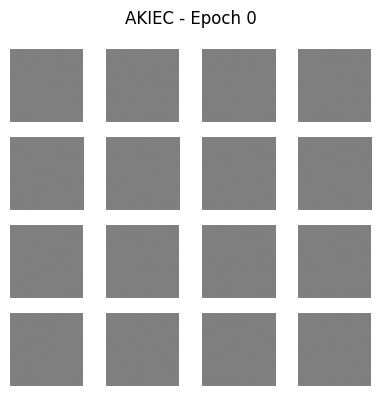

Epoch 2 — G_loss: 0.7710, D_loss: 1.0192
Epoch 3 — G_loss: 0.8742, D_loss: 0.8087
Epoch 4 — G_loss: 1.0657, D_loss: 0.6562
Epoch 5 — G_loss: 1.1534, D_loss: 0.6246
Epoch 6 — G_loss: 1.2065, D_loss: 0.6022
Epoch 7 — G_loss: 1.2311, D_loss: 0.6028
Epoch 8 — G_loss: 1.3305, D_loss: 0.6170
Epoch 9 — G_loss: 1.3352, D_loss: 0.6086
Epoch 10 — G_loss: 1.2205, D_loss: 0.7222
Epoch 11 — G_loss: 1.4310, D_loss: 0.6182
Epoch 12 — G_loss: 1.6556, D_loss: 0.5030
Epoch 13 — G_loss: 1.9455, D_loss: 0.3609
Epoch 14 — G_loss: 2.0932, D_loss: 0.3220
Epoch 15 — G_loss: 2.3141, D_loss: 0.2683
Epoch 16 — G_loss: 2.5194, D_loss: 0.2151
Epoch 17 — G_loss: 2.7735, D_loss: 0.1769
Epoch 18 — G_loss: 2.9366, D_loss: 0.1382
Epoch 19 — G_loss: 3.2412, D_loss: 0.1198
Epoch 20 — G_loss: 3.3641, D_loss: 0.1032
Epoch 21 — G_loss: 3.4069, D_loss: 0.0916
Epoch 22 — G_loss: 3.5442, D_loss: 0.0790
Epoch 23 — G_loss: 3.7204, D_loss: 0.0634
Epoch 24 — G_loss: 3.8237, D_loss: 0.0629
Epoch 25 — G_loss: 3.7819, D_loss: 0.0531


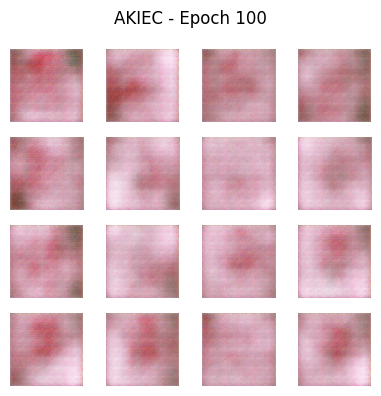

Epoch 102 — G_loss: 0.6861, D_loss: 1.4499
Epoch 103 — G_loss: 0.6541, D_loss: 1.4814
Epoch 104 — G_loss: 0.6853, D_loss: 1.4479
Epoch 105 — G_loss: 0.6711, D_loss: 1.4067
Epoch 106 — G_loss: 0.6947, D_loss: 1.4710
Epoch 107 — G_loss: 0.6776, D_loss: 1.4840
Epoch 108 — G_loss: 0.7169, D_loss: 1.4422
Epoch 109 — G_loss: 0.7583, D_loss: 1.4175
Epoch 110 — G_loss: 0.7399, D_loss: 1.4049
Epoch 111 — G_loss: 0.7103, D_loss: 1.4443
Epoch 112 — G_loss: 0.6643, D_loss: 1.4518
Epoch 113 — G_loss: 0.7064, D_loss: 1.3836
Epoch 114 — G_loss: 0.7075, D_loss: 1.4351
Epoch 115 — G_loss: 0.7149, D_loss: 1.4045
Epoch 116 — G_loss: 0.7345, D_loss: 1.3942
Epoch 117 — G_loss: 0.7502, D_loss: 1.3339
Epoch 118 — G_loss: 0.7503, D_loss: 1.3444
Epoch 119 — G_loss: 0.7074, D_loss: 1.3959
Epoch 120 — G_loss: 0.7405, D_loss: 1.3814
Epoch 121 — G_loss: 0.7309, D_loss: 1.3328
Epoch 122 — G_loss: 0.7408, D_loss: 1.3532
Epoch 123 — G_loss: 0.7138, D_loss: 1.4133
Epoch 124 — G_loss: 0.7598, D_loss: 1.3598
Epoch 125 —

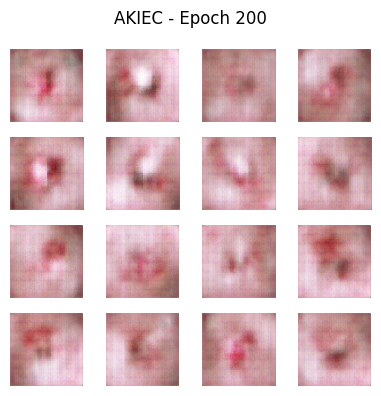

Epoch 202 — G_loss: 0.7245, D_loss: 1.3787
Epoch 203 — G_loss: 0.7364, D_loss: 1.3496
Epoch 204 — G_loss: 0.7054, D_loss: 1.4086
Epoch 205 — G_loss: 0.7072, D_loss: 1.3852
Epoch 206 — G_loss: 0.7094, D_loss: 1.3814
Epoch 207 — G_loss: 0.6890, D_loss: 1.3860
Epoch 208 — G_loss: 0.7288, D_loss: 1.3668
Epoch 209 — G_loss: 0.6795, D_loss: 1.3911
Epoch 210 — G_loss: 0.6944, D_loss: 1.3780
Epoch 211 — G_loss: 0.6832, D_loss: 1.3686
Epoch 212 — G_loss: 0.6803, D_loss: 1.3791
Epoch 213 — G_loss: 0.7042, D_loss: 1.3485
Epoch 214 — G_loss: 0.7029, D_loss: 1.3832
Epoch 215 — G_loss: 0.7075, D_loss: 1.3701
Epoch 216 — G_loss: 0.7011, D_loss: 1.3578
Epoch 217 — G_loss: 0.6758, D_loss: 1.4162
Epoch 218 — G_loss: 0.6780, D_loss: 1.3994
Epoch 219 — G_loss: 0.7070, D_loss: 1.3576
Epoch 220 — G_loss: 0.6951, D_loss: 1.3693
Epoch 221 — G_loss: 0.6934, D_loss: 1.3835
Epoch 222 — G_loss: 0.6967, D_loss: 1.3875
Epoch 223 — G_loss: 0.6944, D_loss: 1.3483
Epoch 224 — G_loss: 0.7048, D_loss: 1.3658
Epoch 225 —

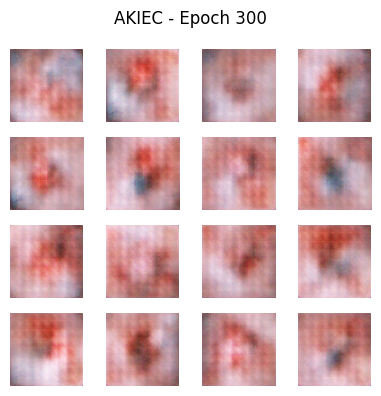

Epoch 302 — G_loss: 0.7062, D_loss: 1.3892
Epoch 303 — G_loss: 0.7136, D_loss: 1.3805
Epoch 304 — G_loss: 0.7036, D_loss: 1.3817
Epoch 305 — G_loss: 0.6958, D_loss: 1.4136
Epoch 306 — G_loss: 0.6994, D_loss: 1.4207
Epoch 307 — G_loss: 0.7073, D_loss: 1.3851
Epoch 308 — G_loss: 0.7232, D_loss: 1.3695
Epoch 309 — G_loss: 0.7255, D_loss: 1.3626
Epoch 310 — G_loss: 0.7061, D_loss: 1.4165
Epoch 311 — G_loss: 0.6715, D_loss: 1.4320
Epoch 312 — G_loss: 0.6994, D_loss: 1.3825
Epoch 313 — G_loss: 0.7258, D_loss: 1.3281
Epoch 314 — G_loss: 0.6964, D_loss: 1.4109
Epoch 315 — G_loss: 0.6822, D_loss: 1.4713
Epoch 316 — G_loss: 0.7678, D_loss: 1.3213
Epoch 317 — G_loss: 0.7489, D_loss: 1.3131
Epoch 318 — G_loss: 0.6932, D_loss: 1.3963
Epoch 319 — G_loss: 0.6659, D_loss: 1.4646
Epoch 320 — G_loss: 0.6882, D_loss: 1.3770
Epoch 321 — G_loss: 0.7134, D_loss: 1.3248
Epoch 322 — G_loss: 0.6897, D_loss: 1.3813
Epoch 323 — G_loss: 0.7630, D_loss: 1.4005
Epoch 324 — G_loss: 0.7854, D_loss: 1.3531
Epoch 325 —

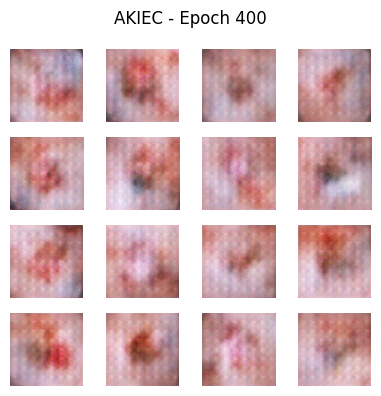

Epoch 402 — G_loss: 0.6605, D_loss: 1.4346
Epoch 403 — G_loss: 0.6642, D_loss: 1.4562
Epoch 404 — G_loss: 0.6936, D_loss: 1.3788
Epoch 405 — G_loss: 0.7199, D_loss: 1.3106
Epoch 406 — G_loss: 0.6888, D_loss: 1.3581
Epoch 407 — G_loss: 0.6481, D_loss: 1.4475
Epoch 408 — G_loss: 0.6941, D_loss: 1.4010
Epoch 409 — G_loss: 0.7357, D_loss: 1.3710
Epoch 410 — G_loss: 0.7114, D_loss: 1.3862
Epoch 411 — G_loss: 0.6762, D_loss: 1.4344
Epoch 412 — G_loss: 0.7044, D_loss: 1.4030
Epoch 413 — G_loss: 0.7484, D_loss: 1.3522
Epoch 414 — G_loss: 0.6960, D_loss: 1.3536
Epoch 415 — G_loss: 0.6840, D_loss: 1.4200
Epoch 416 — G_loss: 0.7114, D_loss: 1.3902
Epoch 417 — G_loss: 0.7370, D_loss: 1.3604
Epoch 418 — G_loss: 0.6949, D_loss: 1.3868
Epoch 419 — G_loss: 0.6772, D_loss: 1.4092
Epoch 420 — G_loss: 0.6636, D_loss: 1.4157
Epoch 421 — G_loss: 0.6887, D_loss: 1.3857
Epoch 422 — G_loss: 0.6896, D_loss: 1.3467
Epoch 423 — G_loss: 0.6993, D_loss: 1.3856
Epoch 424 — G_loss: 0.6587, D_loss: 1.4393
Epoch 425 —

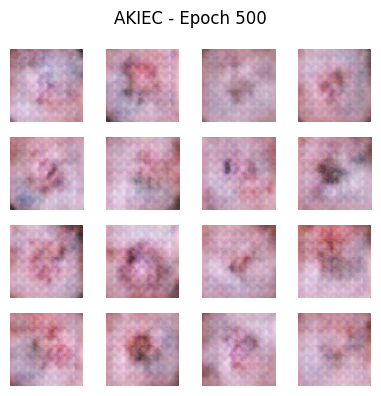

Epoch 502 — G_loss: 0.6748, D_loss: 1.4183
Epoch 503 — G_loss: 0.7457, D_loss: 1.3572
Epoch 504 — G_loss: 0.7631, D_loss: 1.3303
Epoch 505 — G_loss: 0.7184, D_loss: 1.3635
Epoch 506 — G_loss: 0.6813, D_loss: 1.4152
Epoch 507 — G_loss: 0.6824, D_loss: 1.4067
Epoch 508 — G_loss: 0.6811, D_loss: 1.3775
Epoch 509 — G_loss: 0.6539, D_loss: 1.4019
Epoch 510 — G_loss: 0.6542, D_loss: 1.4164
Epoch 511 — G_loss: 0.6982, D_loss: 1.3729
Epoch 512 — G_loss: 0.7390, D_loss: 1.3488
Epoch 513 — G_loss: 0.7140, D_loss: 1.3777
Epoch 514 — G_loss: 0.6836, D_loss: 1.4324
Epoch 515 — G_loss: 0.7035, D_loss: 1.4081
Epoch 516 — G_loss: 0.7171, D_loss: 1.3471
Epoch 517 — G_loss: 0.7149, D_loss: 1.3871
Epoch 518 — G_loss: 0.6738, D_loss: 1.4026
Epoch 519 — G_loss: 0.7371, D_loss: 1.3484
Epoch 520 — G_loss: 0.7320, D_loss: 1.3342
Epoch 521 — G_loss: 0.6855, D_loss: 1.3827
Epoch 522 — G_loss: 0.6734, D_loss: 1.4196
Epoch 523 — G_loss: 0.6879, D_loss: 1.4092
Epoch 524 — G_loss: 0.6677, D_loss: 1.3627
Epoch 525 —

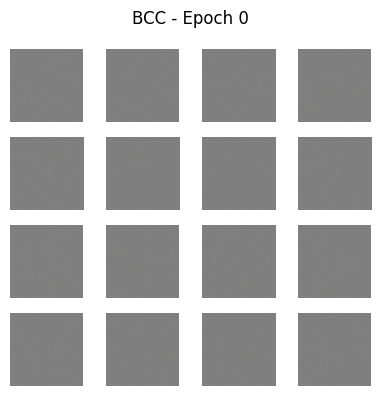

Epoch 2 — G_loss: 0.8114, D_loss: 0.8330
Epoch 3 — G_loss: 1.0359, D_loss: 0.6573
Epoch 4 — G_loss: 1.0821, D_loss: 0.6425
Epoch 5 — G_loss: 1.2243, D_loss: 0.6190
Epoch 6 — G_loss: 1.5886, D_loss: 0.4806
Epoch 7 — G_loss: 1.6812, D_loss: 0.4601
Epoch 8 — G_loss: 1.8712, D_loss: 0.4242
Epoch 9 — G_loss: 2.2171, D_loss: 0.3065
Epoch 10 — G_loss: 2.6286, D_loss: 0.2186
Epoch 11 — G_loss: 2.8687, D_loss: 0.1902
Epoch 12 — G_loss: 3.2791, D_loss: 0.1643
Epoch 13 — G_loss: 3.4239, D_loss: 0.1008
Epoch 14 — G_loss: 3.7151, D_loss: 0.0800
Epoch 15 — G_loss: 3.8631, D_loss: 0.0750
Epoch 16 — G_loss: 3.2483, D_loss: 0.1321
Epoch 17 — G_loss: 1.3716, D_loss: 1.6199
Epoch 18 — G_loss: 0.8552, D_loss: 1.3967
Epoch 19 — G_loss: 0.9451, D_loss: 1.3262
Epoch 20 — G_loss: 1.0514, D_loss: 1.3541
Epoch 21 — G_loss: 1.1605, D_loss: 1.1121
Epoch 22 — G_loss: 1.1379, D_loss: 1.0550
Epoch 23 — G_loss: 1.1517, D_loss: 1.1116
Epoch 24 — G_loss: 1.0572, D_loss: 1.1366
Epoch 25 — G_loss: 1.0151, D_loss: 1.2910


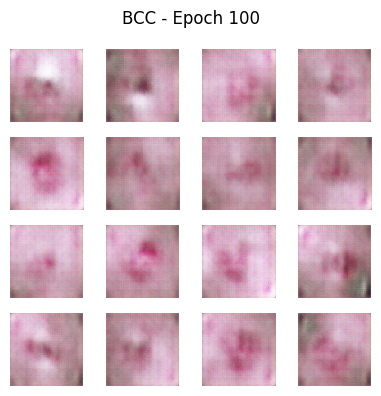

Epoch 102 — G_loss: 0.7372, D_loss: 1.3202
Epoch 103 — G_loss: 0.7327, D_loss: 1.3599
Epoch 104 — G_loss: 0.7201, D_loss: 1.3663
Epoch 105 — G_loss: 0.7163, D_loss: 1.3629
Epoch 106 — G_loss: 0.6813, D_loss: 1.3839
Epoch 107 — G_loss: 0.7277, D_loss: 1.3445
Epoch 108 — G_loss: 0.7045, D_loss: 1.4089
Epoch 109 — G_loss: 0.7320, D_loss: 1.3872
Epoch 110 — G_loss: 0.7236, D_loss: 1.3483
Epoch 111 — G_loss: 0.7116, D_loss: 1.3635
Epoch 112 — G_loss: 0.7248, D_loss: 1.3659
Epoch 113 — G_loss: 0.7407, D_loss: 1.3288
Epoch 114 — G_loss: 0.7423, D_loss: 1.3703
Epoch 115 — G_loss: 0.7102, D_loss: 1.3891
Epoch 116 — G_loss: 0.7503, D_loss: 1.2987
Epoch 117 — G_loss: 0.7323, D_loss: 1.4057
Epoch 118 — G_loss: 0.7301, D_loss: 1.3788
Epoch 119 — G_loss: 0.7125, D_loss: 1.3620
Epoch 120 — G_loss: 0.6915, D_loss: 1.3847
Epoch 121 — G_loss: 0.7011, D_loss: 1.4543
Epoch 122 — G_loss: 0.7228, D_loss: 1.3874
Epoch 123 — G_loss: 0.7088, D_loss: 1.3852
Epoch 124 — G_loss: 0.7308, D_loss: 1.3899
Epoch 125 —

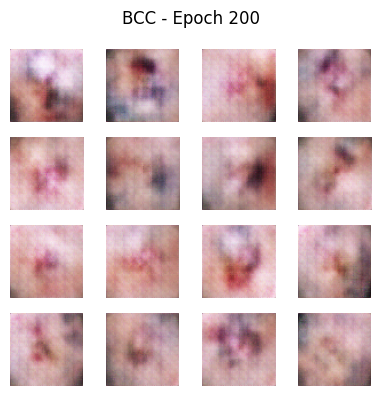

Epoch 202 — G_loss: 0.6573, D_loss: 1.4221
Epoch 203 — G_loss: 0.7038, D_loss: 1.3649
Epoch 204 — G_loss: 0.7255, D_loss: 1.3990
Epoch 205 — G_loss: 0.7090, D_loss: 1.4149
Epoch 206 — G_loss: 0.7195, D_loss: 1.3809
Epoch 207 — G_loss: 0.6916, D_loss: 1.3989
Epoch 208 — G_loss: 0.6992, D_loss: 1.4109
Epoch 209 — G_loss: 0.6987, D_loss: 1.3810


KeyboardInterrupt: 

In [14]:
# Count images in each class
class_counts = {}
base_dir = "C:\\Users\\devgo\\OneDrive\\Desktop\\project\\data\\processed_images"
for label in os.listdir(base_dir):
    class_path = os.path.join(base_dir, label)
    if os.path.isdir(class_path):
        count = len([f for f in os.listdir(class_path) if f.endswith('.jpg')])
        class_counts[label] = count

max_count = max(class_counts.values())
print("🔢 Image counts per class:", class_counts)
print(f"📊 Max class size = {max_count}")

# Run GAN training and augmentation
for label in os.listdir(base_dir):
    path = os.path.join(base_dir, label)
    if os.path.isdir(path):
        train_gan_for_class(label, path, target_total=max_count)
